In [1]:
# %pip install sidetable
# %conda install -c conda-forge --yes scienceplots

In [1]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [2]:
plt.style.use(['science','no-latex'])

In [3]:
os.getcwd()

'/home/jmuires/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [4]:
os.chdir("../../../")
os.getcwd()

'/home/jmuires/source/urban-mobility-simulation'

In [5]:
from simulation.helper.time import SimulationTimeConverter

In [6]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [200]:
runs = pd.read_csv("data/output/run_configs.csv")
runs = runs.sort_values(by="timestamp")
runs.tail(50)

,timestamp,experiment,duration_sim_min,duration_real_sec,n_vehicles,n_charging_stations,capacity_per_station,kW,seed,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
179,20240818_14:09:07,WITS_benchmark_uncoordinated.py,20160,4479.944531,500,9,6.0,22.0,43,0.128279,0.127841,0.999569,NaN,random_SOC_init
175,20240818_14:09:07,WITS_benchmark_uncoordinated.py,20160,4373.347208,500,9,6.0,22.0,43,0.126825,0.128586,0.999514,NaN,random_SOC_init
176,20240818_14:09:15,WITS_benchmark_uncoordinated_separated.py,20160,4380.999733,500,9,3.0,22.0,43,0.127398,0.127599,0.999623,0.999623,random_SOC_init
180,20240818_14:09:16,WITS_benchmark_uncoordinated_separated.py,20160,4491.129089,500,9,3.0,22.0,43,0.127474,0.127865,0.999440,0.999440,random_SOC_init
178,20240818_14:09:17,WITS_benchmark_uncoordinated_separated.py,20160,4381.253291,500,9,3.0,22.0,43,0.127608,0.127554,0.999629,0.999629,random_SOC_init
177,20240818_14:09:17,WITS_benchmark_uncoordinated_separated.py,20160,4380.471015,500,9,3.0,22.0,43,0.127545,0.127685,0.999397,0.999397,random_SOC_init
172,20240818_14:09:18,WITS_benchmark_uncoordinated_separated.py,20160,4268.224766,500,9,3.0,22.0,43,0.127464,0.127404,0.999644,0.999644,random_SOC_init
156,20240818_14:11:38,WITS_benchmark_uncoordinated.py,20160,2659.084046,500,9,6.0,22.0,43,0.257551,0.256143,0.999633,NaN,random_SOC_init
160,20240818_14:11:39,WITS_benchmark_uncoordinated.py,20160,2717.983179,500,9,6.0,22.0,43,0.260803,0.254184,0.999627,NaN,random_SOC_init
149,20240818_14:11:40,WITS_benchmark_uncoordinated.py,20160,2524.587301,500,9,6.0,22.0,43,0.256797,0.259070,0.999668,NaN,random_SOC_init


In [1164]:
runs[['timestamp', 'experiment', 'service_level_fleet_0', 'service_level_fleet_1', 'avg_util_infra_0', 'avg_util_infra_1', 'notes']].tail(6)

,timestamp,experiment,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
59,20240816_21:49:17,WITS_coordinated_shared_charging.py,0.237791,0.224590,0.893526,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."
57,20240816_21:49:24,WITS_benchmark_uncoordinated.py,0.016855,0.019172,0.247841,NaN,random_SOC_init
58,20240816_21:49:28,WITS_benchmark_uncoordinated_separated.py,0.019269,0.020253,0.271982,0.271982,random_SOC_init
62,20240817_02:45:39,WITS_coordinated_shared_charging.py,0.233909,0.229237,0.879787,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."
60,20240817_02:45:57,WITS_benchmark_uncoordinated.py,0.019166,0.018476,0.256914,NaN,random_SOC_init
61,20240817_02:50:05,WITS_benchmark_uncoordinated_separated.py,0.019391,0.019254,0.258984,0.258984,random_SOC_init


In [104]:
RUN_UNCOORDINATED = "20240818_00:21:56"
RUN_SEPERATE = "20240818_00:22:01"
RUN_COORDINATED = "20240818_00:21:48"

In [105]:
SIM_DAYS = parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME") // 1440 + 1

In [106]:
PLOT_RESAMPLING = '1h'

## Auction

In [107]:
auction_tracking = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_auction.csv")

In [108]:
auction_tracking

,time,participant_id,location,_bids,_result
0,5,0,872664521ffffff,"[(1, 0.6075141673159978), (3, 0.78004370862983...","(3, 0.7800437086298341)"
1,5,0,872664c10ffffff,"[(1, 0.4128402905238287), (1, 0.48967950228433...","(4, 0.5243211398175819)"
2,5,0,872664c1affffff,"[(1, 0.433426885056306), (1, 0.530251608615683...","(4, 0.7882271519788269)"
3,5,0,872664c1effffff,"[(1, 0.42244189616074795), (1, 0.4333430655745...","(2, 0.7882271519788269)"
4,5,0,872664ca9ffffff,"[(1, 0.4229531438748934), (1, 0.62130106007353...","(3, 0.6574639184426451)"
...,...,...,...,...,...
11244,20080,1,872664521ffffff,"[(1, 0.6085320671496703)]","(1, 0.4227418230247941)"
11245,20085,0,872664521ffffff,"[(1, 0.4227418230247941)]","(0, 0.4227418230247941)"
11246,20085,1,872664521ffffff,"[(1, 0.6085320671496703)]","(1, 0.4227418230247941)"
11247,20090,0,872664521ffffff,"[(1, 0.4227418230247941)]","(0, 0.4227418230247941)"


In [109]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_datetime))

In [110]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

In [111]:
auction_tracking[(auction_tracking['_bids.total_capacity'] - auction_tracking['_result.capacity']) <0]

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid
111,365,0,872664c1effffff,"[(2, 0.7882271519788269), (1, 1.0)]","(4, 0.7882271519788269)",2024-01-01 06:05:00,0.788227,4,3,0.894114


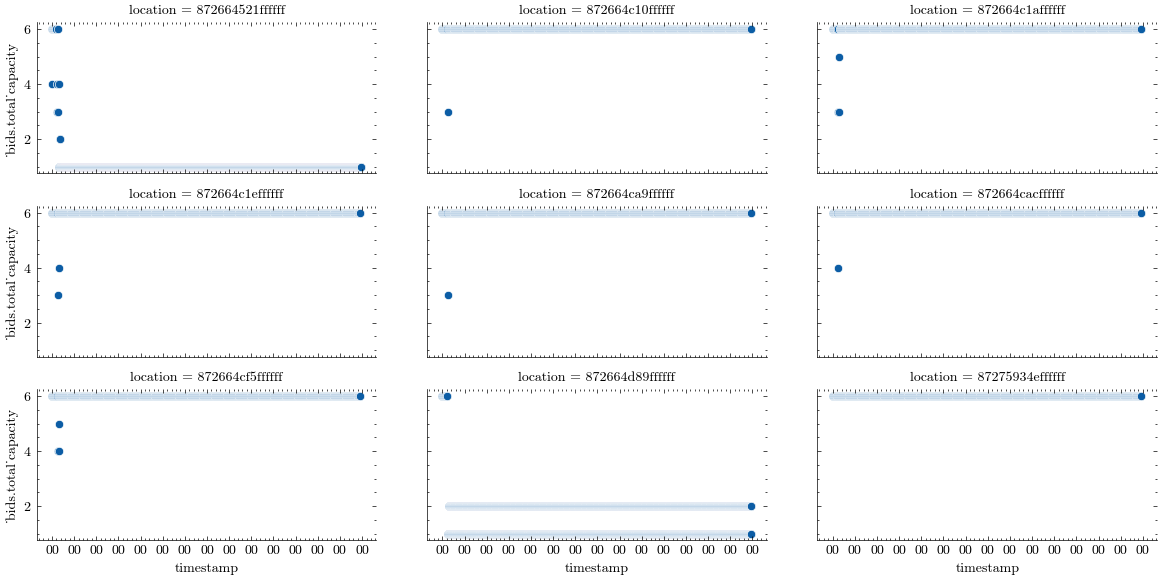

In [112]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_bids.total_capacity", col="location", col_wrap=3, kind="scatter", height=2, aspect = 2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=24))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

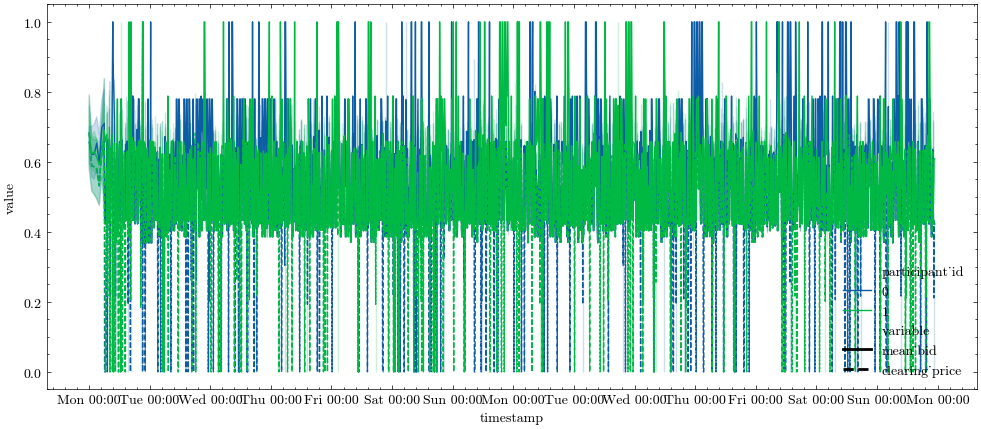

In [113]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(12,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [114]:
auction_tracking_hourly = auction_tracking.groupby('participant_id').resample('6h', on='timestamp').agg({'_bids.mean_bid': 'mean', '_result.clearing_price': 'mean'}).reset_index()

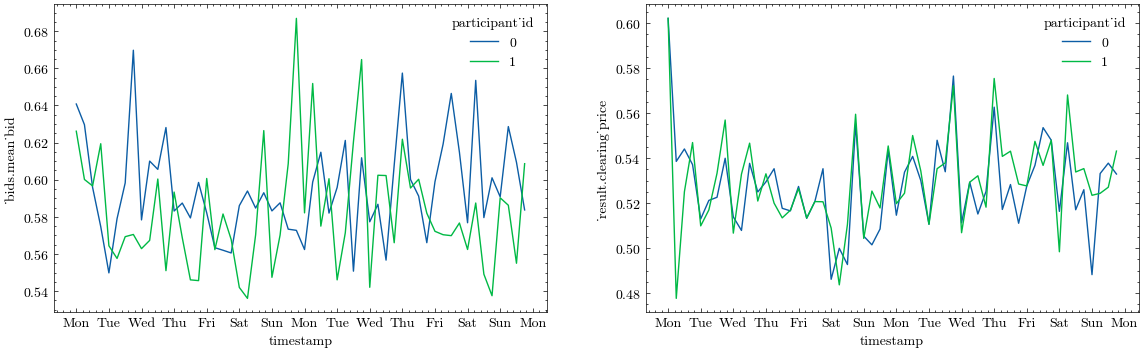

In [115]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_bids.mean_bid", hue="participant_id", ax=ax[0])
sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_result.clearing_price", hue="participant_id", ax=ax[1])

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Vehicles

In [116]:
vehicle_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_vehicles.csv")

In [117]:
# rename time axis
vehicle_tracking_coordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_coordinated['time'] = pd.to_datetime(vehicle_tracking_coordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

### fleet state (SOC)

In [118]:
RECHARGE_THRESHOLD = [float(x) for x in parser.get("RIDE_HAILING_OPERATOR", "RECHARGE_THRESHOLD").split(",")]

vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['hour'] = vehicle_tracking_coordinated['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)


In [119]:
vehicle_tracking_coordinated['n_suggested'] = vehicle_tracking_coordinated['_suggested'].apply(lambda x: np.sum(eval(x)))

In [120]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [121]:
vehicle_tracking_coordinated['_state_PARKING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_coordinated['_state_CHARGING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_coordinated['_state_DRIVING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_coordinated['_state_RELOCATING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_coordinated['_state_PRE_SERVICE'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_coordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_coordinated['_state_RESERVED'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

In [122]:
# resample for plotting
vehicle_tracking_coordinated = vehicle_tracking_coordinated.groupby('_fleet').resample(PLOT_RESAMPLING, on='time').agg({
    'fleet_average_SOC': 'mean', 
    'fleet_number_low_SOC': 'mean',
    '_vdt': 'max',
    'n_suggested': 'mean',
    '_state_PARKING': 'mean',
    '_state_CHARGING': 'mean',
    '_state_DRIVING': 'mean',
    '_state_RELOCATING': 'mean',
    '_state_PRE_SERVICE': 'mean',
    '_state_MOVING_TO_PICK_UP_POS': 'mean',
    '_state_RESERVED': 'mean'
}).reset_index()

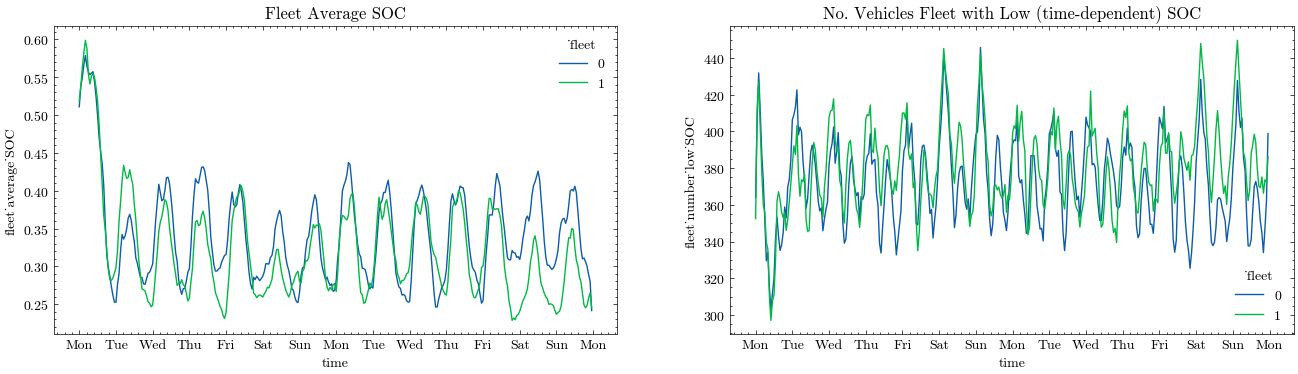

In [123]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low (time-dependent) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

### states

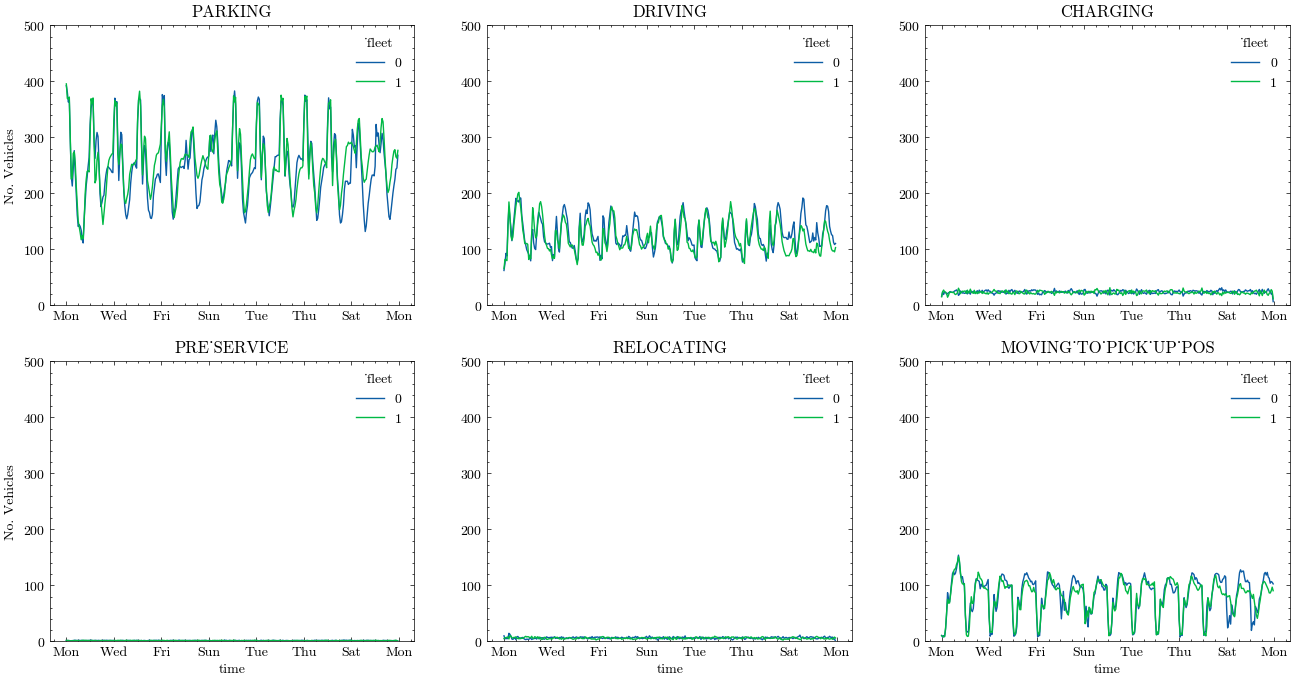

In [124]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

<Axes: xlabel='time', ylabel='n_suggested'>

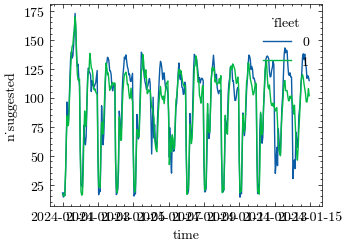

In [125]:
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='n_suggested', hue='_fleet')

## Charging Stations

In [126]:
charging_station_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_charging_stations.csv")

In [127]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [128]:
charging_station_tracking_coordinated['utilization'] = charging_station_tracking_coordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

In [129]:
# rename time axis
charging_station_tracking_coordinated['time'] = pd.to_datetime(charging_station_tracking_coordinated['time'].apply(SimulationTimeConverter.as_datetime))

In [130]:
# resample for faster plotting
charging_station_tracking_coordinated = charging_station_tracking_coordinated.groupby('_location').resample(PLOT_RESAMPLING, on='time').agg({
    'utilization': 'mean',
    '_plugs.count': 'mean',
    '_plugs.queuesize': 'mean'
}).reset_index()

In [131]:
charging_station_tracking_coordinated['system_wide_utilization'] = charging_station_tracking_coordinated.groupby('time')['utilization'].transform('mean')

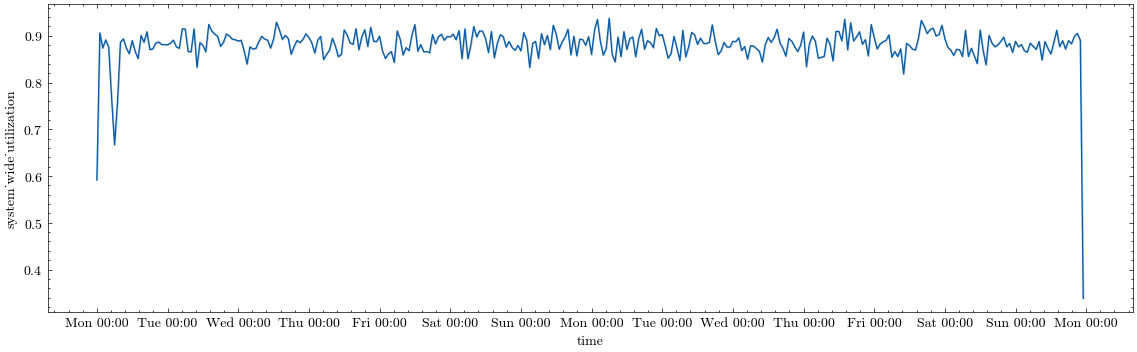

In [132]:
fig, ax = plt.subplots(1,1, figsize=(14,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

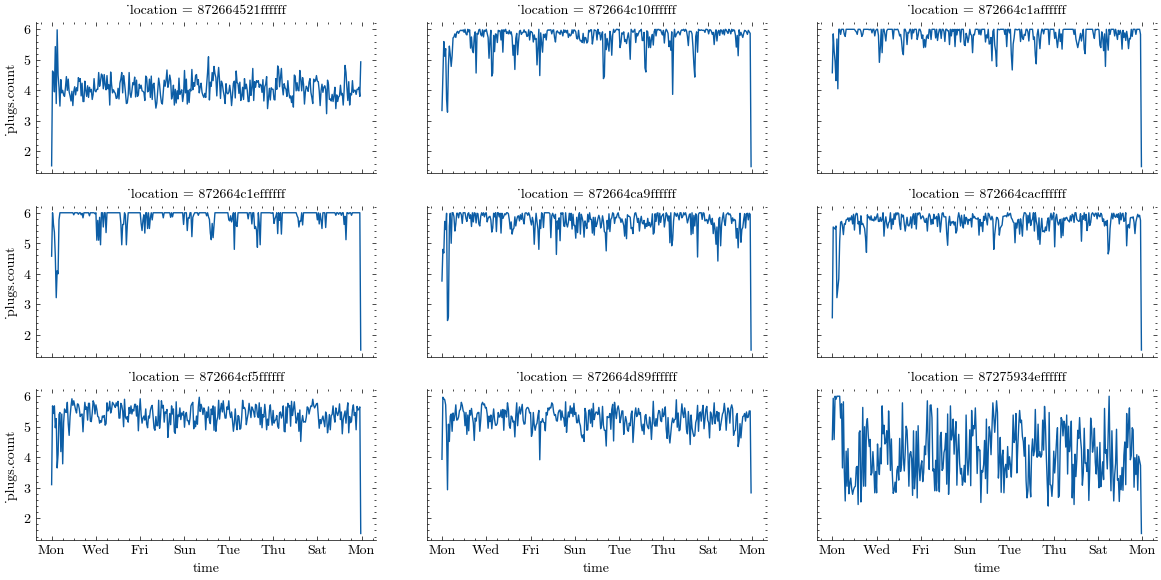

In [133]:
charging_station_tracking_coordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_coordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [134]:
# fig, ax = plt.subplots(1,1, figsize=(8,4))

# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.count', label='util', ax=ax)
# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.queuesize', label='queue size', ax=ax)

# ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

## Transactions

In [135]:
transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_transactions.csv")

In [136]:
RESAMPLE_RATE = '1h'

In [137]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'])
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'])
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [138]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
# transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
# transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

# transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
# transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

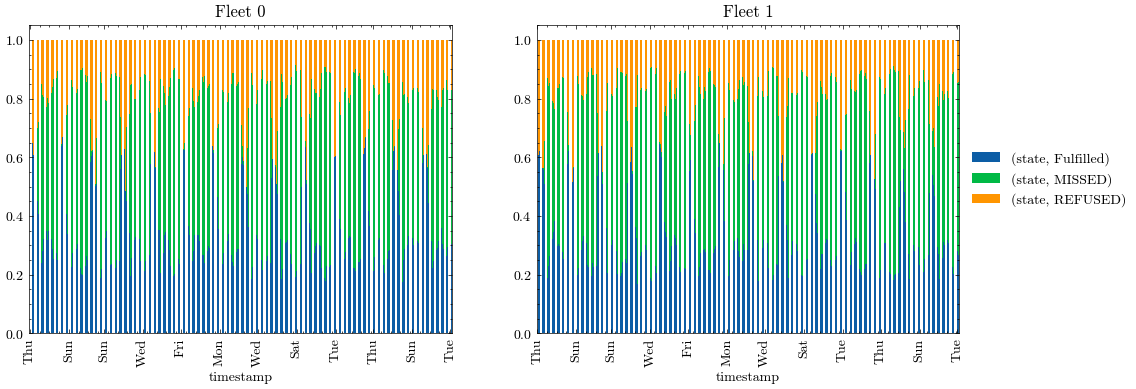

In [139]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

(0.0, 1.0)

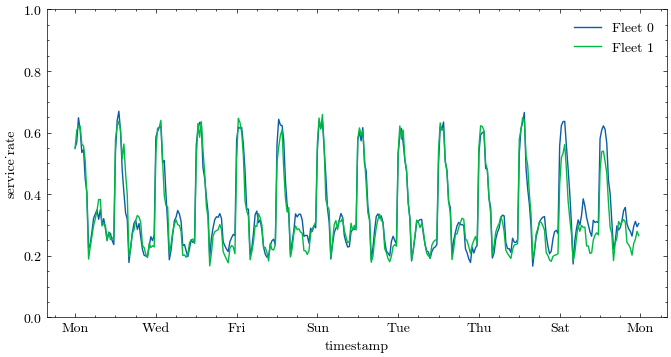

In [140]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [141]:
vehicle_tracking_coordinated['fleet_vdt'] = vehicle_tracking_coordinated['_vdt'].apply(lambda x: sum(eval(x)))

In [210]:
vehicle_tracking_coordinated.iloc[-1]['_vdt']

'[4912320.223418567, 5441633.330198612, 5949431.948692464, 4038864.9456448704, 5277112.542906382, 5018117.406969079, 2924009.4551782594, 5306380.778359721, 5749938.9775285255, 3146851.864800246, 5866175.44740137, 2802814.9911586726, 5131361.296430375, 5281230.154234372, 1590229.6400502746, 5789249.635214182, 5116114.913070298, 5992228.832425268, 3957150.1887052422, 2395860.320150557, 6050476.696736459, 1394528.7604260657, 2072172.5391952212, 5490875.537619243, 4930460.114773556, 1206346.2202730728, 5507036.6461376855, 5312250.06214644, 4494837.534530226, 4051780.935929378, 5222023.110079386, 4760487.512151829, 6099229.82948822, 4963742.915925466, 4874033.266470581, 5986985.658872767, 2227091.3394157, 5635189.060608373, 5267843.462344569, 5094518.777556621, 5470617.75282883, 5777764.505320676, 5873438.35135429, 3914965.8228338747, 562941.7553765994, 5079080.645241562, 5727308.363921118, 5623746.937447698, 2549608.1433629147, 4185901.8449931764, 4255518.157884048, 2198926.282075125, 5226

In [142]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [143]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

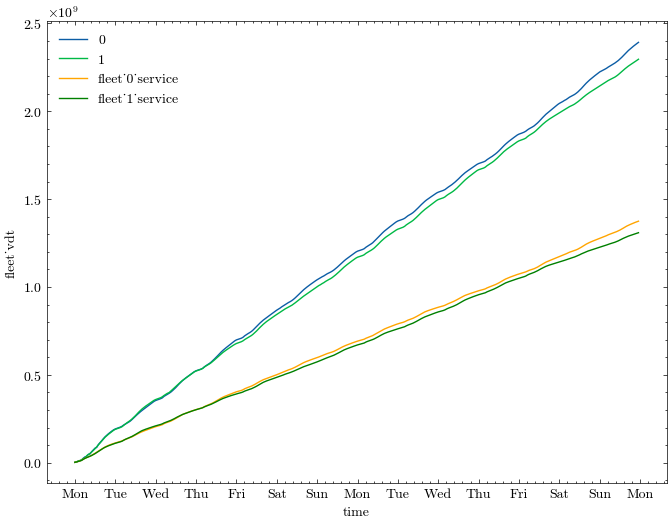

In [144]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [145]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking_coordinated.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [146]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [147]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [148]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [149]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
2024-01-01 00:00:00,1.792562e+06,2.203160e+06,1.621736e+06,1.621736e+06,1.667026e+06,1.667026e+06,0.095297,0.243347,1.792562e+06,2.203160e+06
2024-01-01 01:00:00,2.973337e+06,5.401745e+06,2.342116e+06,3.963853e+06,2.622854e+06,4.289881e+06,-0.983541,0.179996,1.180775e+06,3.198585e+06
2024-01-01 02:00:00,8.645553e+06,8.528114e+06,2.894581e+06,6.858434e+06,2.549672e+06,6.839553e+06,0.489691,0.184462,5.672216e+06,3.126369e+06
2024-01-01 03:00:00,1.191354e+07,1.179829e+07,2.826855e+06,9.685289e+06,2.641855e+06,9.481407e+06,0.134985,0.192137,3.267983e+06,3.270175e+06
2024-01-01 04:00:00,1.277229e+07,1.643917e+07,3.846571e+06,1.353186e+07,3.645639e+06,1.312705e+07,-3.479226,0.214451,8.587580e+05,4.640884e+06


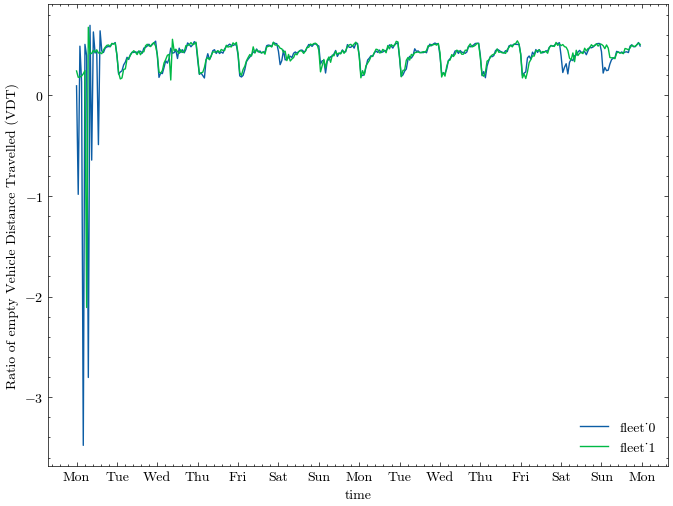

In [150]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Service Tasks

In [151]:
task_transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_task_transactions.csv")

In [152]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'])

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'])

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']
task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [153]:
task_transactions_fleet_0

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,6,15,74.999999,461,TaskState.FINISHED,0,87275934effffff,8.012795,59.999999,22.000000,2024-01-01 00:06:00,68.999999
1,6,15,74.999999,248,TaskState.FINISHED,0,872664ca9ffffff,7.786509,59.999999,22.000000,2024-01-01 00:06:00,68.999999
2,6,15,74.999999,107,TaskState.FINISHED,0,872664c1affffff,7.725698,59.999999,22.000000,2024-01-01 00:06:00,68.999999
3,6,15,74.999999,98,TaskState.FINISHED,0,872664c1affffff,7.514468,59.999999,22.000000,2024-01-01 00:06:00,68.999999
4,6,15,74.999999,436,TaskState.FINISHED,0,87275934effffff,7.477049,59.999999,22.000000,2024-01-01 00:06:00,68.999999
...,...,...,...,...,...,...,...,...,...,...,...,...
9221,20046,20055,20114.999999,359,TaskState.FINISHED,0,87275934effffff,-10.779658,49.220341,18.047458,2024-01-14 22:06:00,68.999999
9222,20046,20055,20114.999999,373,TaskState.FINISHED,0,872664521ffffff,-16.780178,43.219821,15.847268,2024-01-14 22:06:00,68.999999
9223,20046,20055,20114.999999,140,TaskState.FINISHED,0,87275934effffff,-24.948901,35.051098,12.852069,2024-01-14 22:06:00,68.999999
9224,20046,20055,20114.999999,347,TaskState.FINISHED,0,87275934effffff,-35.341640,24.658359,9.041398,2024-01-14 22:06:00,68.999999


In [154]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                    
TaskState.FINISHED           9220
TaskState.MISSED_TIMESLOT       6
Name: count, dtype: int64

state                         
TaskState.FINISHED                8862
TaskState.MISSED_TIMESLOT           10
TaskState.EXECUTING_RELOCATION       5
Name: count, dtype: int64

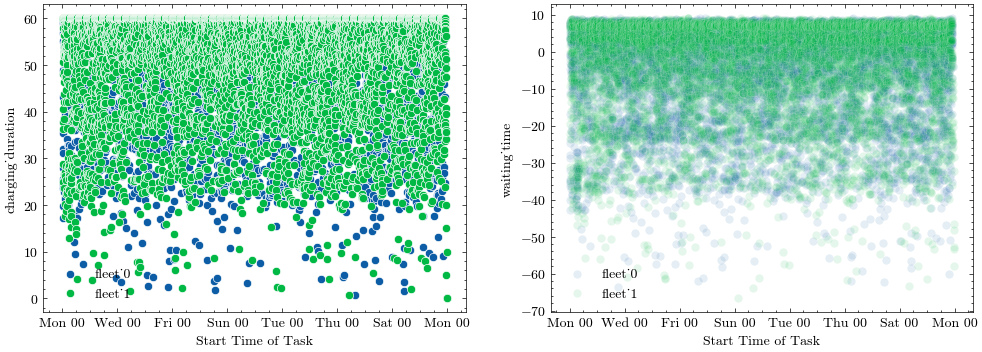

In [155]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1], alpha=.1)
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1], alpha=.1)

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

<Axes: xlabel='waiting_time', ylabel='Density'>

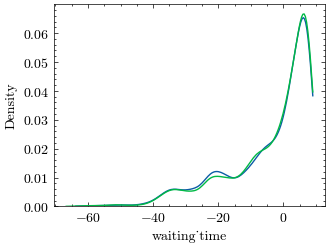

In [156]:
sns.kdeplot(data=task_transactions_fleet_0, x='waiting_time', label='fleet_0', cut=0)
sns.kdeplot(data=task_transactions_fleet_1, x='waiting_time', label='fleet_1',cut=0)

In [157]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

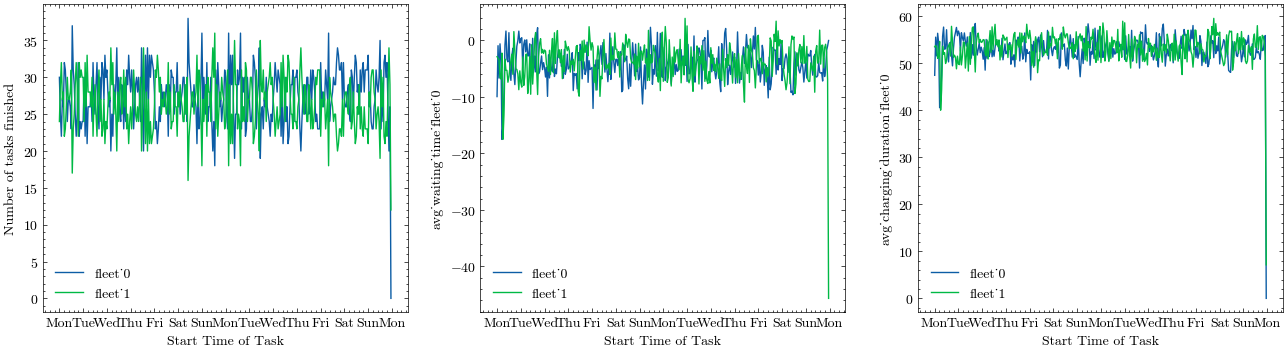

In [158]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS + 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [159]:
date_range = range(0,parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME"), 15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [160]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_datetime)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'])

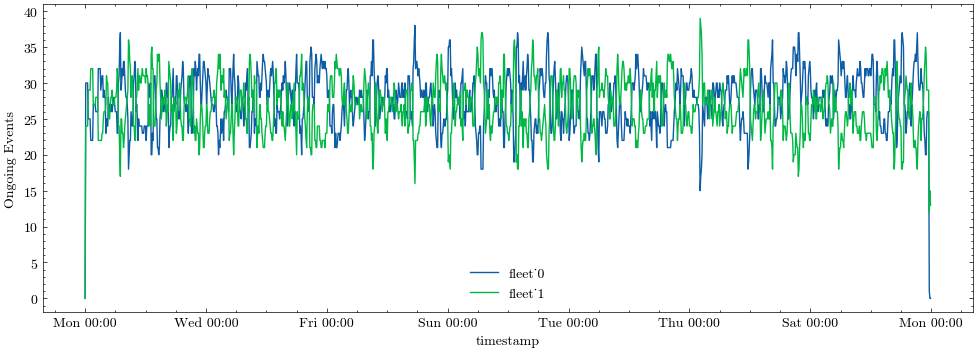

In [161]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


In [162]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [163]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [164]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [165]:
tasks_incl_price.head()

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,6,15,74.999999,461,TaskState.FINISHED,0,87275934effffff,8.012795,59.999999,22.0,2024-01-01 00:06:00,68.999999,15.0,NaN,NaN,9.46
1,6,15,74.999999,248,TaskState.FINISHED,0,872664ca9ffffff,7.786509,59.999999,22.0,2024-01-01 00:06:00,68.999999,15.0,NaN,NaN,9.46
2,6,15,74.999999,107,TaskState.FINISHED,0,872664c1affffff,7.725698,59.999999,22.0,2024-01-01 00:06:00,68.999999,15.0,NaN,NaN,9.46
3,6,15,74.999999,98,TaskState.FINISHED,0,872664c1affffff,7.514468,59.999999,22.0,2024-01-01 00:06:00,68.999999,15.0,NaN,NaN,9.46
4,6,15,74.999999,436,TaskState.FINISHED,0,87275934effffff,7.477049,59.999999,22.0,2024-01-01 00:06:00,68.999999,15.0,NaN,NaN,9.46


In [166]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

/home/jmuires/anaconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from font(s) cmr10.
  func(*args, **kwargs)
/home/jmuires/anaconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


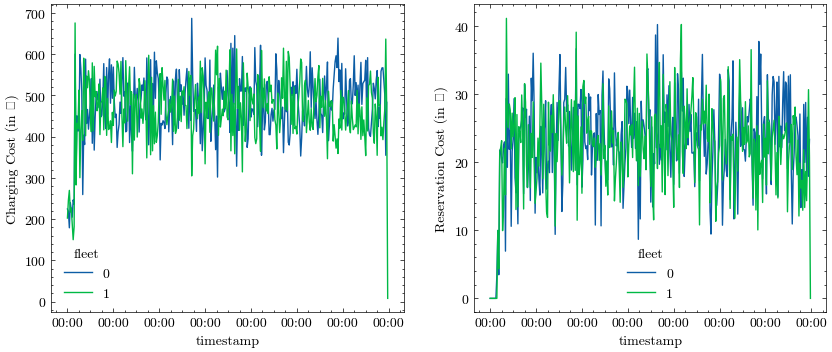

In [167]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmarks: Single Infrastructure, No Coordination // Seperate Infrastructures

In [182]:
charging_station_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_charging_stations.csv")
vehicle_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_vehicles.csv")

charging_station_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_charging_stations.csv")
vehicle_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_vehicles.csv")

In [169]:
# rename time axis
vehicle_tracking_uncoordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_uncoordinated['time'] = pd.to_datetime(vehicle_tracking_uncoordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

vehicle_tracking_seperate.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_seperate['time'] = pd.to_datetime(vehicle_tracking_seperate['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

In [170]:
max_soc = parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")

vehicle_tracking_uncoordinated['fleet_average_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / max_soc
vehicle_tracking_uncoordinated['hour'] = vehicle_tracking_uncoordinated['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_uncoordinated['fleet_number_low_SOC'] = vehicle_tracking_uncoordinated.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

vehicle_tracking_seperate['fleet_average_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / max_soc
vehicle_tracking_seperate['hour'] = vehicle_tracking_seperate['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_seperate['fleet_number_low_SOC'] = vehicle_tracking_seperate.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

In [171]:
vehicle_tracking_uncoordinated['_state_PARKING'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_uncoordinated['_state_CHARGING'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_uncoordinated['_state_DRIVING'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_uncoordinated['_state_RELOCATING'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_uncoordinated['_state_PRE_SERVICE'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_uncoordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_uncoordinated['_state_RESERVED'] = vehicle_tracking_uncoordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

vehicle_tracking_seperate['_state_PARKING'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_seperate['_state_CHARGING'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_seperate['_state_DRIVING'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_seperate['_state_RELOCATING'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_seperate['_state_PRE_SERVICE'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_seperate['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_seperate['_state_RESERVED'] = vehicle_tracking_seperate['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

In [172]:
# resample for plotting
vehicle_tracking_uncoordinated = vehicle_tracking_uncoordinated.groupby('_fleet').resample(PLOT_RESAMPLING, on='time').agg({
    'fleet_average_SOC': 'mean', 
    'fleet_number_low_SOC': 'mean',
    '_state_PARKING': 'mean',
    '_state_CHARGING': 'mean',
    '_state_DRIVING': 'mean',
    '_state_RELOCATING': 'mean',
    '_state_PRE_SERVICE': 'mean',
    '_state_MOVING_TO_PICK_UP_POS': 'mean',
    '_state_RESERVED': 'mean'
}).reset_index()
vehicle_tracking_seperate = vehicle_tracking_seperate.groupby('_fleet').resample(PLOT_RESAMPLING, on='time').agg({
    'fleet_average_SOC': 'mean', 
    'fleet_number_low_SOC': 'mean',
    '_state_PARKING': 'mean',
    '_state_CHARGING': 'mean',
    '_state_DRIVING': 'mean',
    '_state_RELOCATING': 'mean',
    '_state_PRE_SERVICE': 'mean',
    '_state_MOVING_TO_PICK_UP_POS': 'mean',
    '_state_RESERVED': 'mean'
}).reset_index()

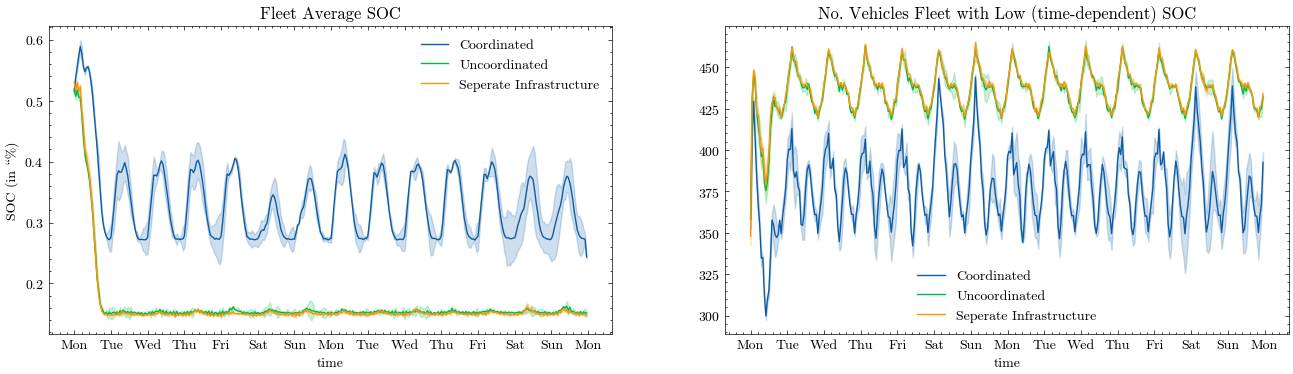

In [173]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_average_SOC', ax = ax[0], label='Seperate Infrastructure')

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Seperate Infrastructure')

ax[0].set_title('Fleet Average SOC')
ax[0].set_ylabel('SOC (in \%)')
ax[1].set_title(f'No. Vehicles Fleet with Low (time-dependent) SOC')
ax[1].set_ylabel('')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

In [183]:
charging_station_tracking_uncoordinated['utilization'] = charging_station_tracking_uncoordinated['_plugs.count'] / CHARGING_STATION_CAPACITY
charging_station_tracking_seperate['utilization'] = charging_station_tracking_seperate['_plugs.count'] / (CHARGING_STATION_CAPACITY / 2)

In [184]:
# rename time axis
charging_station_tracking_uncoordinated['time'] = pd.to_datetime(charging_station_tracking_uncoordinated['time'].apply(SimulationTimeConverter.as_datetime))
charging_station_tracking_seperate['time'] = pd.to_datetime(charging_station_tracking_seperate['time'].apply(SimulationTimeConverter.as_datetime))

In [185]:
# resample for faster plotting
charging_station_tracking_uncoordinated = charging_station_tracking_uncoordinated.groupby('_location').resample(PLOT_RESAMPLING, on='time').agg({
    'utilization': 'mean',
    '_plugs.count': 'mean',
    '_plugs.queuesize': 'mean'
}).reset_index()

In [186]:
charging_station_tracking_uncoordinated['system_wide_utilization'] = charging_station_tracking_uncoordinated.groupby('time')['utilization'].transform('mean')
charging_station_tracking_seperate['system_wide_utilization'] = charging_station_tracking_seperate.groupby('time')['utilization'].transform('mean')

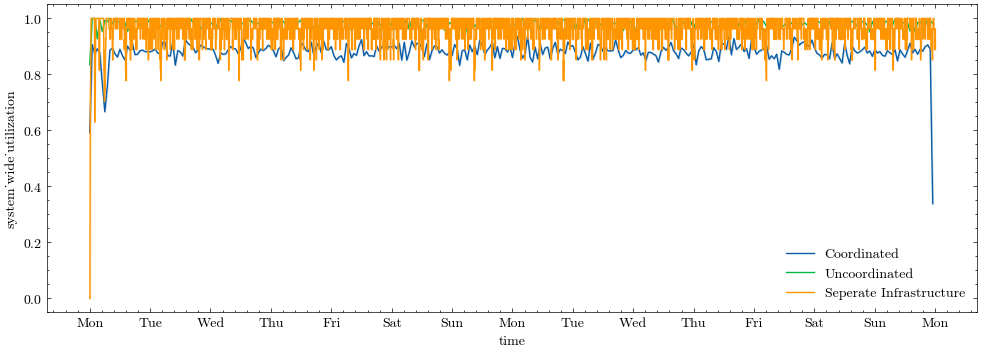

In [178]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', label= 'Coordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_uncoordinated, x='time', y='system_wide_utilization', label= 'Uncoordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_seperate, x='time', y='system_wide_utilization', label= 'Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

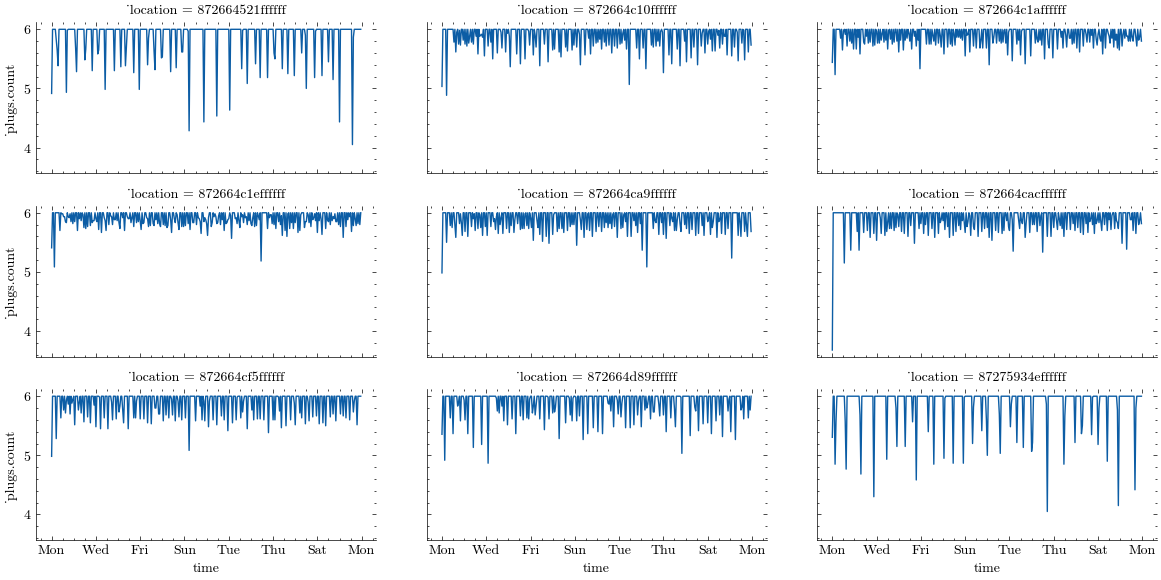

In [179]:
charging_station_tracking_uncoordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_uncoordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

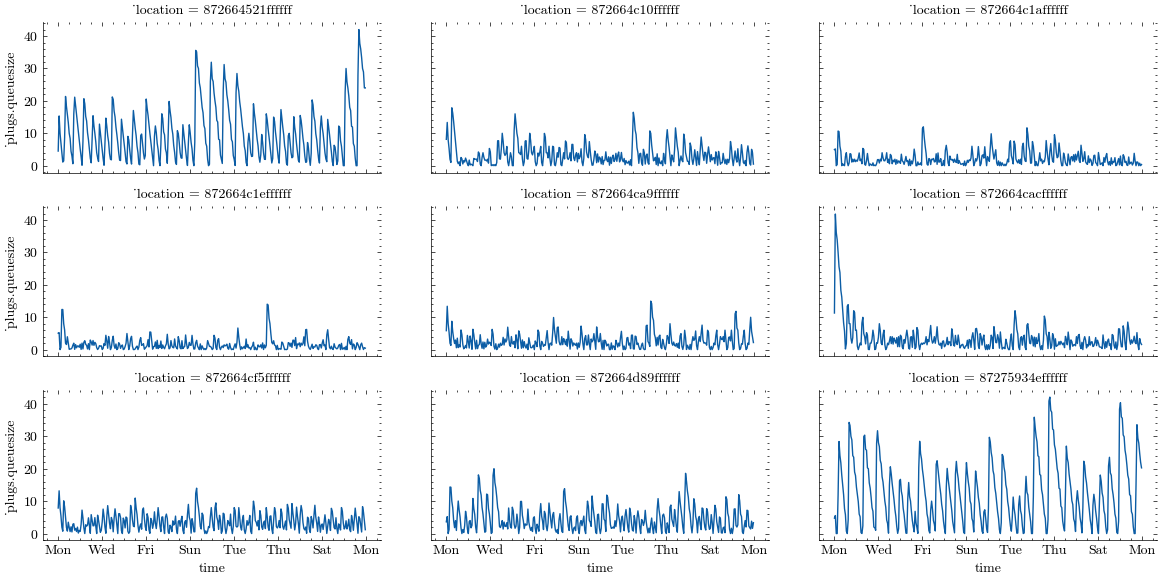

In [187]:
charging_station_tracking_uncoordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_uncoordinated, x='time', y='_plugs.queuesize', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [188]:
transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_transactions.csv")

transactions_fleet_0_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_0_transactions.csv")
transactions_fleet_1_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_1_transactions.csv")

In [189]:
transactions_fleet_0_uncoordinated['timestamp'] = transactions_fleet_0_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_0_uncoordinated['timestamp'])
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_uncoordinated['timestamp'] = transactions_fleet_1_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_1_uncoordinated['timestamp'])
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_0_seperate['timestamp'] = transactions_fleet_0_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_seperate['timestamp'] = pd.to_datetime(transactions_fleet_0_seperate['timestamp'])
transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_seperate['timestamp'] = transactions_fleet_1_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_seperate['timestamp'] = pd.to_datetime(transactions_fleet_1_seperate['timestamp'])
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()


# normalize
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated_resampled.div(transactions_fleet_0_uncoordinated_resampled.sum(axis=1), axis=0)
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated_resampled.div(transactions_fleet_1_uncoordinated_resampled.sum(axis=1), axis=0)

transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate_resampled.div(transactions_fleet_0_seperate_resampled.sum(axis=1), axis=0)
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate_resampled.div(transactions_fleet_1_seperate_resampled.sum(axis=1), axis=0)

# calc service rate, per fleet and overall
transactions_fleet_0_uncoordinated_resampled['service_rate'] = transactions_fleet_0_uncoordinated_resampled[('state', 'Fulfilled')]
transactions_fleet_1_uncoordinated_resampled['service_rate'] = transactions_fleet_1_uncoordinated_resampled[('state', 'Fulfilled')]

transactions_fleet_0_seperate_resampled['service_rate'] = transactions_fleet_0_seperate_resampled[('state', 'Fulfilled')]
transactions_fleet_1_seperate_resampled['service_rate'] = transactions_fleet_1_seperate_resampled[('state', 'Fulfilled')]

service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_seperate_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

service_rate_coordinated['service_rate'] = service_rate_coordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_uncoordinated['service_rate'] = service_rate_uncoordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_seperate['service_rate'] = service_rate_seperate[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)

/tmp/ipykernel_633613/2214906733.py:32: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_633613/2214906733.py:33: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/tmp/ipykernel_633613/2214906733.py:34: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].m

(0.0, 1.0)

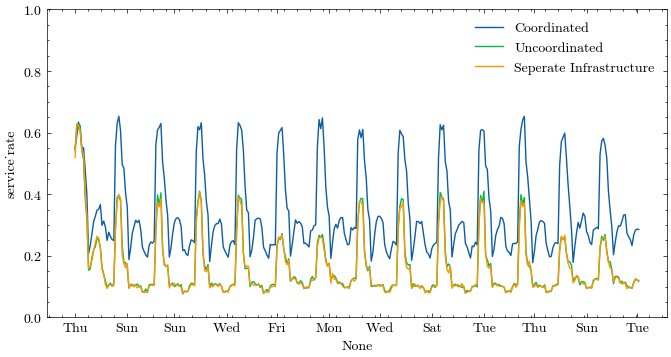

In [190]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

sns.lineplot(data=service_rate_coordinated, x = service_rate_coordinated.index, y = 'service_rate', label='Coordinated', ax=ax)
sns.lineplot(data=service_rate_uncoordinated, x = service_rate_uncoordinated.index, y = 'service_rate', label='Uncoordinated', ax=ax)
sns.lineplot(data=service_rate_seperate, x = service_rate_seperate.index, y = 'service_rate', label='Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

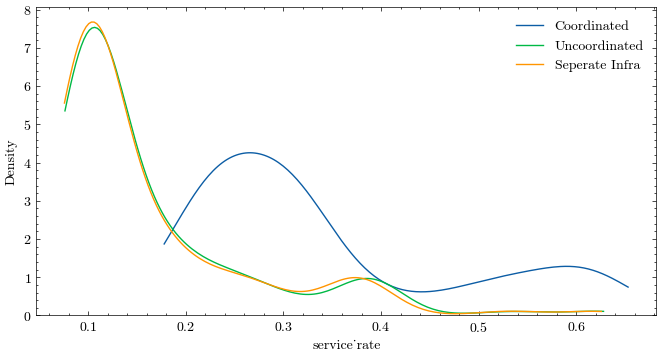

In [191]:
fig, ax = plt.subplots(1,1, figsize=(8,4))

sns.kdeplot(data = service_rate_coordinated, x='service_rate', label='Coordinated', cut=0, ax=ax)
sns.kdeplot(data = service_rate_uncoordinated, x='service_rate', label='Uncoordinated', cut=0, ax=ax)
sns.kdeplot(data = service_rate_seperate, x='service_rate', label='Seperate Infra', cut=0, ax=ax)

ax.legend()

ValueError: Could not interpret value `_state_PARKING` for `y`. An entry with this name does not appear in `data`.

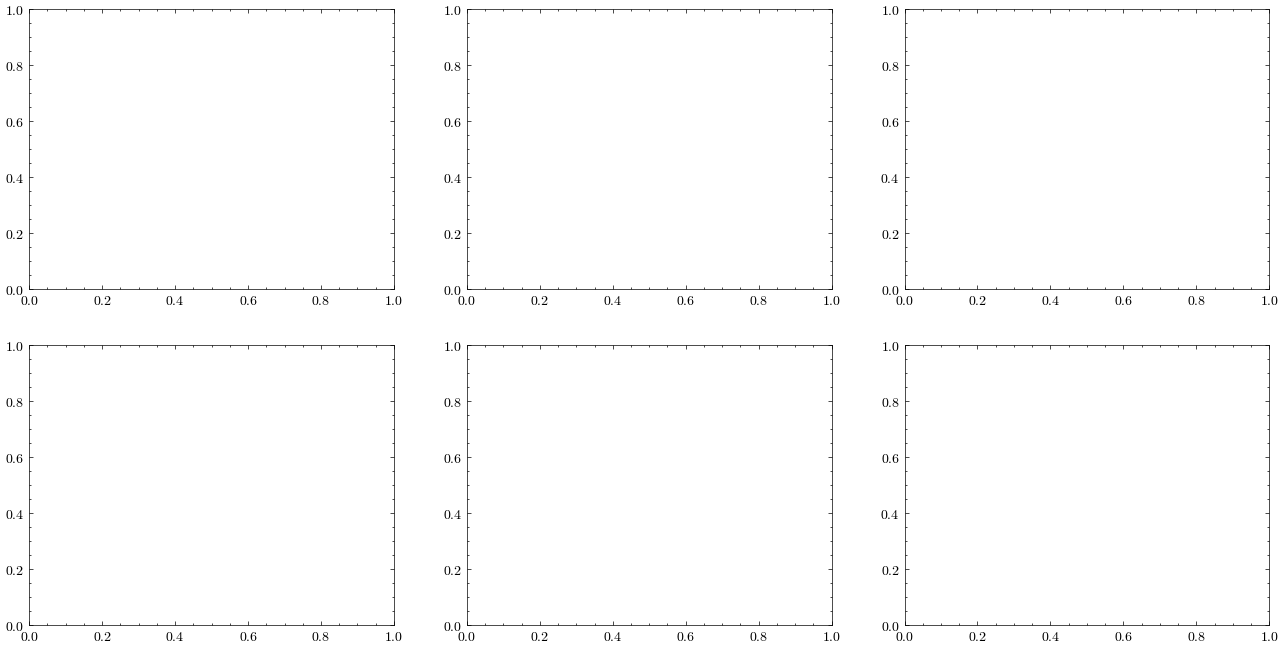

In [192]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_uncoordinated_resampled[[('state')]].plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_uncoordinated_resampled[[('state')]].plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [ ]:
len(transactions_fleet_0) + len(transactions_fleet_1)

In [ ]:
transactions_fleet_0_uncoordinated[transactions_fleet_0_uncoordinated['state'] == 'Fulfilled'].groupby('vehicle_id').agg({'destination': 'last'}).value_counts()

In [ ]:
transactions_fleet_0_uncoordinated[transactions_fleet_0_uncoordinated['state'] == 'Fulfilled'].groupby('vehicle_id').agg({'destination': 'last'}).value_counts()

In [ ]:
# TODO: waiting time benchmarks

In [ ]:
task_transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_task_transactions.csv")
task_transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_task_transactions.csv")

In [ ]:
task_transactions_fleet_0_uncoordinated['timestamp'] = task_transactions_fleet_0_uncoordinated['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(task_transactions_fleet_0_uncoordinated['timestamp'])

task_transactions_fleet_1_uncoordinated['timestamp'] = task_transactions_fleet_1_uncoordinated['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(task_transactions_fleet_1_uncoordinated['timestamp'])

task_transactions_fleet_0_uncoordinated['duration'] = task_transactions_fleet_0_uncoordinated['end_time'] - task_transactions_fleet_0_uncoordinated['start_time']
task_transactions_fleet_1_uncoordinated['duration'] = task_transactions_fleet_1_uncoordinated['end_time'] - task_transactions_fleet_1_uncoordinated['start_time']

In [ ]:
display(task_transactions_fleet_0_uncoordinated.value_counts(subset=['state']))
display(task_transactions_fleet_1_uncoordinated.value_counts(subset=['state']))

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0_uncoordinated, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1_uncoordinated, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0_uncoordinated, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1], alpha=.1)
sns.scatterplot(data=task_transactions_fleet_1_uncoordinated, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1], alpha=.1)

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

<Axes: xlabel='waiting_time', ylabel='Density'>

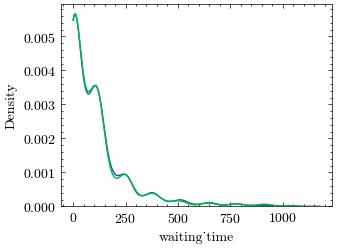

In [201]:
sns.kdeplot(data=task_transactions_fleet_0_uncoordinated, x='waiting_time', label='fleet_0', cut=0)
sns.kdeplot(data=task_transactions_fleet_1_uncoordinated, x='waiting_time', label='fleet_1',cut=0)

In [196]:
vehicle_tracking_uncoordinated['_vdt'].apply(lambda x: sum(eval(x)))

0        0.000000e+00
1        0.000000e+00
2        0.000000e+00
3        0.000000e+00
4        7.026379e+02
             ...     
40313    1.064389e+09
40314    1.065687e+09
40315    1.064442e+09
40316    1.065714e+09
40317    1.064498e+09
Name: _vdt, Length: 40318, dtype: float64

### compare one day with Anthony's results

In [ ]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

In [ ]:
benchmark_no_coordination

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [ ]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

In [ ]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS +  1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [ ]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


In [ ]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [ ]:
metrics_no_coordination

In [ ]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

In [ ]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

### other stuff

In [ ]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [ ]:
transactions_fleet_0['pick_up_time'].describe()